# Анализ процентной ставки

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

candidates = [
    Path("data/processed/application_train_features.csv"),
    Path("../data/processed/application_train_features.csv"),
]

file_path = next(
    (path for path in candidates if path.exists()),
    None,
)

if file_path is None:
    raise FileNotFoundError(
        "Не найден application_train_features.csv в data/processed"
    )

df = pd.read_csv(file_path)

print(f"Загружен файл: {file_path}")
print(f"Размер датасета: {df.shape}")

Загружен файл: ..\data\processed\application_train_features.csv
Размер датасета: (307511, 14)


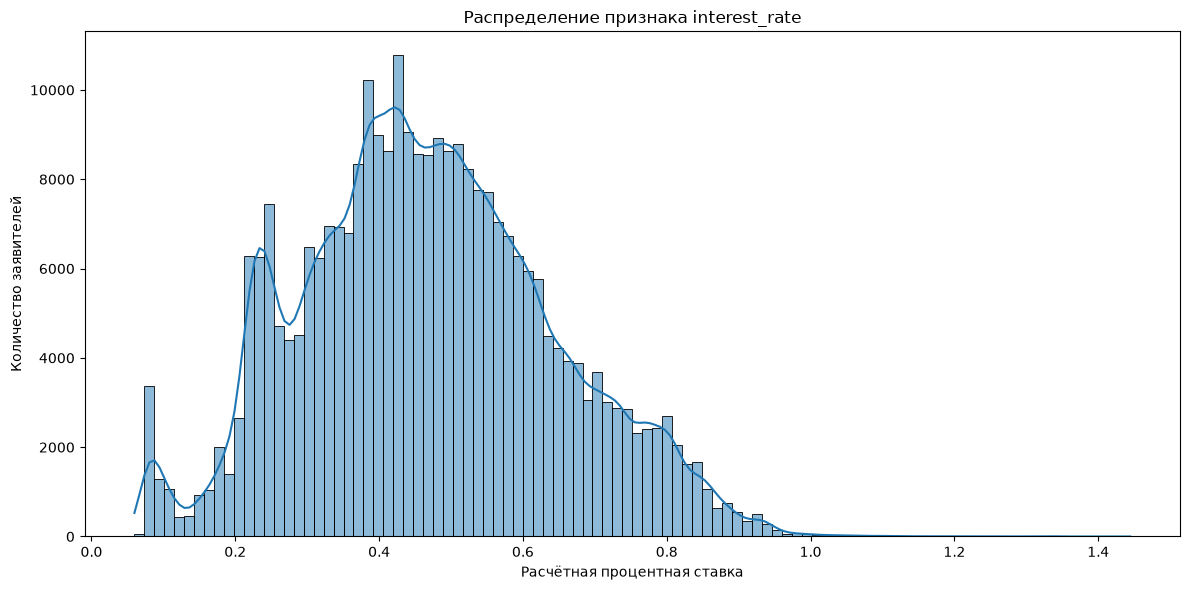

In [2]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="interest_rate",
    bins=100,
    kde=True,
)

plt.title("Распределение признака interest_rate")
plt.xlabel("Расчётная процентная ставка")
plt.ylabel("Количество заявителей")
plt.tight_layout()
plt.show()

# Вывод признаков, содержащих информацию о доме

In [5]:
from app.modelling.features.application_train_test_features import (
    get_columns_by_description,
)

description_df = pd.read_csv(
    "../data/home-credit-default-risk/HomeCredit_columns_description.csv",
    encoding="cp1252",
)

apprt_features = get_columns_by_description(
    description_df,
    "Normalized information about building where the client lives",
)

print("\n".join(apprt_features))

APARTMENTS_AVG
BASEMENTAREA_AVG
YEARS_BEGINEXPLUATATION_AVG
YEARS_BUILD_AVG
COMMONAREA_AVG
ELEVATORS_AVG
ENTRANCES_AVG
FLOORSMAX_AVG
FLOORSMIN_AVG
LANDAREA_AVG
LIVINGAPARTMENTS_AVG
LIVINGAREA_AVG
NONLIVINGAPARTMENTS_AVG
NONLIVINGAREA_AVG
APARTMENTS_MODE
BASEMENTAREA_MODE
YEARS_BEGINEXPLUATATION_MODE
YEARS_BUILD_MODE
COMMONAREA_MODE
ELEVATORS_MODE
ENTRANCES_MODE
FLOORSMAX_MODE
FLOORSMIN_MODE
LANDAREA_MODE
LIVINGAPARTMENTS_MODE
LIVINGAREA_MODE
NONLIVINGAPARTMENTS_MODE
NONLIVINGAREA_MODE
APARTMENTS_MEDI
BASEMENTAREA_MEDI
YEARS_BEGINEXPLUATATION_MEDI
YEARS_BUILD_MEDI
COMMONAREA_MEDI
ELEVATORS_MEDI
ENTRANCES_MEDI
FLOORSMAX_MEDI
FLOORSMIN_MEDI
LANDAREA_MEDI
LIVINGAPARTMENTS_MEDI
LIVINGAREA_MEDI
NONLIVINGAPARTMENTS_MEDI
NONLIVINGAREA_MEDI
FONDKAPREMONT_MODE
HOUSETYPE_MODE
TOTALAREA_MODE
WALLSMATERIAL_MODE
EMERGENCYSTATE_MODE


# Поиск записей, содержащих два различных статуса по одному займу в течение месяца

In [8]:
bureau_balance = pd.read_csv(
    "../data/home-credit-default-risk/bureau_balance.csv",
)

unique_records = bureau_balance.drop_duplicates(
    subset=["SK_ID_BUREAU", "MONTHS_BALANCE", "STATUS"]
)

status_counts = (
    unique_records
    .groupby(["SK_ID_BUREAU", "MONTHS_BALANCE"])["STATUS"]
    .nunique(dropna=False)
)

conflict_keys = status_counts[status_counts > 1].index

print(f"Количество конфликтных сочетаний «кредит — месяц»: {len(conflict_keys)}")

if len(conflict_keys) > 0:
    conflicts = (
        unique_records
        .set_index(["SK_ID_BUREAU", "MONTHS_BALANCE"])
        .loc[conflict_keys]
        .reset_index()
        .sort_values(["SK_ID_BUREAU", "MONTHS_BALANCE"])
    )

    display(conflicts)

Количество конфликтных сочетаний «кредит — месяц»: 0


In [7]:
print("Количество полных дубликатов:", bureau_balance.duplicated().sum())

Количество полных дубликатов: 0
